# Trabalho Prático
-Filipe de Barros Carneiro Silva / filipe.silva.90@edu.ufes.br / 2023101627

-Heitor Pinheiro Sousa / heitor.sousa@edu.ufes.br / 2023100532

-João Vitor Toneto Machado / joao.t.machado@edu.ufes.br / 2024103551

## Introdução
Este trabalho tem por objetivo utilizar dos conceitos aprendidos na disciplina de Introdução à Ciência de Dados para investigar se há relação entre a **descrição** de um livro e o(s) seu(s) **gênero(s)** no nosso conjunto de dados da GoodReads.

A seguir, teremos os passos descritos conforme a metodologia do roteiro do trabalho, bem como explicações sobre as escolhas tomadas.

## IMPORTS

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk import word_tokenize
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
import string
import unidecode
from langdetect import detect, DetectorFactory, LangDetectException
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from scipy.cluster import hierarchy
from sklearn.cluster import AgglomerativeClustering
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import classification_report


## Leitura e pré-processamento
Inicialmente, lemos o `goodreads_books.csv` como um DataFrame e fazemos uma cópia, checamos se está tudo certo com a distribuição de gêneros e se há dados faltantes dentre os atributos que utilizaremos (id, título, descrição e gênero)

In [34]:
df = pd.read_csv('goodreads_books.csv',delimiter=',')
df.head()

,book_id,title,author,description,genre,publication_year,average_rating,ratings_count,num_pages
0,32941127,Black Panther: A Nation Under Our Feet,Ta-Nehisi Coates,A new era for the Black Panther begins as the ...,graphic-novel|fantasy|science-fiction|literary...,2017.0,4.25,52,344.0
1,22929618,the Beastly Pirates,John Kelly,They're called The Beastly Pirates and this fe...,children,2015.0,3.56,8,32.0
2,13550502,"The Ill-Made Knight (William Gold, #1)",Christian Cameron,William Gold comes into the world as his famil...,historical-fiction|literary-fiction|fantasy|no...,2013.0,4.37,790,457.0
3,16059950,The Mystic Princesses and the Whirlpool,P.J. LaRue,Meet The Mystic Princesses - Role models who s...,children|fantasy,2012.0,4.33,9,34.0
4,6684834,88 Short Stories,Guy de Maupassant,Contents: 1. Yvette (Yvette) 2. Our Friends th...,short-stories,1950.0,4.50,2,815.0


<Axes: >

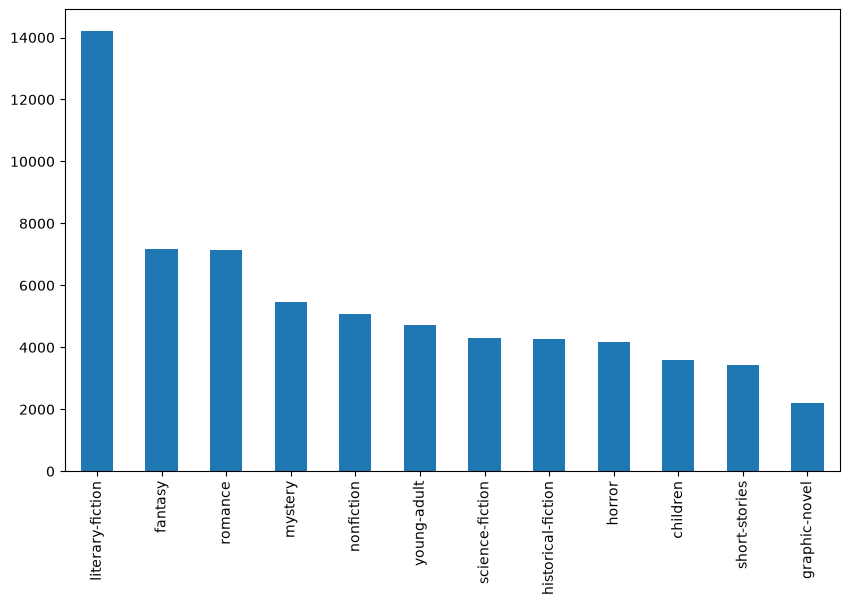

In [35]:
data = df[["book_id","title","genre","description"]].copy()
data["description_raw"] = data.description 
genres = data["genre"].str.get_dummies(sep="|")

genres.sum().sort_values(ascending=False).plot(kind="bar", figsize=(10, 6))

In [36]:
print(data.isna().sum())
print(data.shape)

book_id            0
title              0
genre              0
description        0
description_raw    0
dtype: int64
(25000, 5)


Depois, montamos nossa função de pré-processamento ao texto das descrições, utilizando dos seguintes passos:
1. Tokenização
2. Formatação para lowercase
3. Remoção de caracteres especiais/pontuação
4. Remoção de tokens não alfabéticos
5. Remoção de stopwords da nltk
6. Stemming para filtrar os radicais
7. Concatenação do resultado novamente em string

In [37]:
nltk.download('punkt_tab')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

porter = PorterStemmer()

def preprocessing(text):
    list_tokens = word_tokenize(text)
    list_tokens = [w.lower() for w in list_tokens]

    table = str.maketrans('', '', string.punctuation)
    list_tokens = [w.translate(table) for w in list_tokens]

    list_tokens = [unidecode.unidecode(w).lower() for w in list_tokens]

    words = [word for word in list_tokens if word.isalpha()]
    
    words = [word for word in words if not word in stop_words]

    stemmed = [porter.stem(word) for word in words]
    
    result = " ".join([f"{stem}" for stem in stemmed])

    return result



[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\fbcs2\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\fbcs2\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Adicionalmente, detectamos e removemos descrições que não estão em inglês utilizando a biblioteca langdetect, para manter o nosso conjunto de dados uniforme em inglês. Ao final da filtragem, o número de documentos foi para 24568.

In [38]:
DetectorFactory.seed = 0

def detect_lang(text):
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"

data["lang"] = data.description.apply(detect_lang)
print(data.lang.value_counts().head(10))

data = data[data.lang == "en"].drop(columns="lang").reset_index(drop=True)
print(data.shape)

lang
en    24568
es      132
fr       82
de       48
pt       28
it       25
cy       24
id       19
nl       10
pl        8
Name: count, dtype: int64
(24568, 5)


In [39]:
data.description = data.description.apply(preprocessing)


In [40]:
data.description.to_list()


['new era black panther begin kingdom wakanda enter final day awardwin writer tanehisi coat confront tchalla dramat upheav homeland make lead african nation tougher ever superhuman terrorist group call peopl spark violent upris land fame incred technolog proud warrior tradit thrown turmoil zenzi leader peopl poison populac king former queen shuri spirit make uncanni journey djalia new crew form wakanda surviv must adapt monarch one long line black panther surviv necessari chang heavi lie head wear cowl collect black',
 'call beastli pirat fearsom ugli bunch scour sea pirat gobbl lunch bewar beastli pirat scariest sailor seven sea cutlasstot pirate bunch renegad list dastardli deed endless dare come face face motley crew warn certainli book bedtim unless like pirat bit bite',
 'william gold come world famili slide social ladder head fill tale chivalri instead brand thief must make squir childhood friend sir robert knight determin make name man arm franc william slowli acquir skill knigh

## Construção da matriz TF-IDF
Para reduzir drasticamente o número de termos (colunas) da matriz tf-idf, analizamos o comportamento do número dessas features em função do corte mínimo de frequência de termos, e escolhemos o nosso "cotovelo" em 100. Isso visa facilitar, simultaneamente, tanto a redução de dimensionalidade do TruncatedSVD quanto o agrupamento em si, removendo termos que são específicos demais para serem relevantes ao agrupamento.

min_df=2 => X.shape=(24568, 30632)
min_df=3 => X.shape=(24568, 22790)
min_df=5 => X.shape=(24568, 16613)
min_df=10 => X.shape=(24568, 11122)
min_df=15 => X.shape=(24568, 8871)
min_df=20 => X.shape=(24568, 7499)
min_df=25 => X.shape=(24568, 6567)
min_df=30 => X.shape=(24568, 5912)
min_df=50 => X.shape=(24568, 4228)
min_df=75 => X.shape=(24568, 3202)
min_df=100 => X.shape=(24568, 2633)
min_df=125 => X.shape=(24568, 2262)
min_df=150 => X.shape=(24568, 1957)
min_df=175 => X.shape=(24568, 1725)
min_df=200 => X.shape=(24568, 1539)


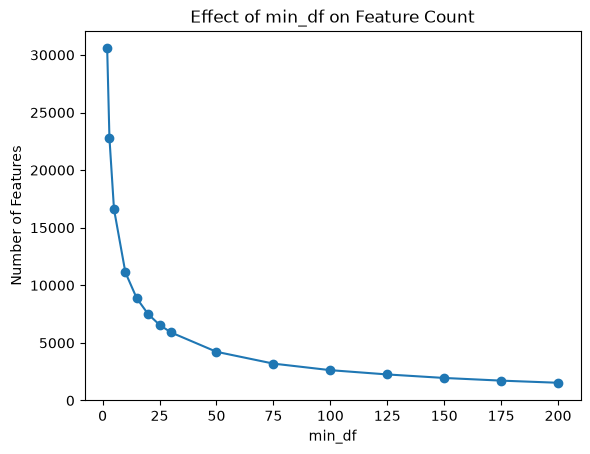

In [41]:
min_df = [2,3,5,10,15,20,25,30,50,75,100,125,150,175,200]
x_columns = []
for df in min_df:
    vectorizer = TfidfVectorizer(min_df=df,sublinear_tf=True)
    X = vectorizer.fit_transform(data.description.to_list())
    x_columns.append(X.shape[1])
    print(f"min_df={df} => X.shape={X.shape}")


plt.plot(min_df, x_columns, marker='o')
plt.xlabel('min_df')
plt.ylim(bottom=0)
plt.ylabel('Number of Features')
plt.title('Effect of min_df on Feature Count')
plt.show()


Adicionalmente, colocamos uma frequência de documento máxima para mitigar stopwords específicas ao conjunto de dados, além de incluir algumas stopwords extras manualmente, baseado nos primeiros resultados obtidos que continham termos "genéricos" para o agrupamento, incluindo pedaços de conjugações quebradas durante o pré-processamento ("ca'nt" virando ["ca", "nt"]).

In [42]:
MIN_DF = 100
MAX_DF = 0.15

extra_stop = ["nt", "ca", "one", "would", "could", "get", "make", "like", "even", "go",
              "book", "novel", "stori", "seri", "author", "read", "publish", "new", "first", "want", "thing"]

vectorizer = TfidfVectorizer(min_df=MIN_DF, max_df=MAX_DF, sublinear_tf=True, stop_words=extra_stop)
X = vectorizer.fit_transform(data.description.to_list())

## Redução de dimensionalidade por TruncatedSVD
Depois, plotamos os valores singulares do SVD para encontrar um joelho de redução de dimensionalidade. O valor de k escolhido foi 100, o que é um bom indicativo, pois condiz com o "padrão" da metodologia LSA para análise de dados textuais, e é possível ver que não há uma redução significativa dos valores singulares de 100 até 300.

In [43]:
MAX_COMPONENTS = 300
svd = TruncatedSVD(n_components=MAX_COMPONENTS, random_state=42)
svd.fit(X)

,"n_components n_components: int, default=2Desired dimensionality of output data.If algorithm='arpack', must be strictly less than the number of features.If algorithm='randomized', must be less than or equal to the number of features.The default value is useful for visualisation. For LSA, a value of100 is recommended.",300
,"random_state random_state: int, RandomState instance or None, default=NoneUsed during randomized svd. Pass an int for reproducible results acrossmultiple function calls.See :term:`Glossary <random_state>`.",42
,"algorithm algorithm: {'arpack', 'randomized'}, default='randomized'SVD solver to use. Either ""arpack"" for the ARPACK wrapper in SciPy(scipy.sparse.linalg.svds), or ""randomized"" for the randomizedalgorithm due to Halko (2009).",'randomized'
,"n_iter n_iter: int, default=5Number of iterations for randomized SVD solver. Not used by ARPACK. Thedefault is larger than the default in:func:`~sklearn.utils.extmath.randomized_svd` to handle sparsematrices that may have large slowly decaying spectrum.",5
,"n_oversamples n_oversamples: int, default=10Number of oversamples for randomized SVD solver. Not used by ARPACK.See :func:`~sklearn.utils.extmath.randomized_svd` for a completedescription... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD solver.Not used by ARPACK. See :func:`~sklearn.utils.extmath.randomized_svd`for more details... versionadded:: 1.1",'auto'
,"tol tol: float, default=0.0Tolerance for ARPACK. 0 means machine precision. Ignored by randomizedSVD solver.",0.0
Name,Type,Value
"components_ components_: ndarray of shape (n_components, n_features)The right singular vectors of the input data.","ndarray[float64](300, 2599)","[[ 0.02, 0.01, 0.02,..., 0.01, 0.01, 0. ], [-0.01,-0. ,-0.01,..., 0.01, 0. ,-0. ], [ 0.01, 0. , 0.02,..., 0. , 0. , 0. ], ..., [ 0.01, 0. ,-0.03,...,-0.01,-0.07,-0.01], [-0.02, 0.01, 0.01,..., 0.02, 0.02, 0. ], [ 0.01,-0.01, 0.05,..., 0.01, 0.04,-0. ]]"
"explained_variance_ explained_variance_: ndarray of shape (n_components,)The variance of the training samples transformed by a projection toeach component.","ndarray[float64](300,)","[0.,0.,0.,...,0.,0.,0.]"
"explained_variance_ratio_ explained_variance_ratio_: ndarray of shape (n_components,)Percentage of variance explained by each of the selected components.","ndarray[float64](300,)","[0.,0.,0.,...,0.,0.,0.]"


In [44]:
singular_values = svd.singular_values_
explained_variance = svd.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
cumulative_variance[-1]

np.float64(0.30739558559828556)

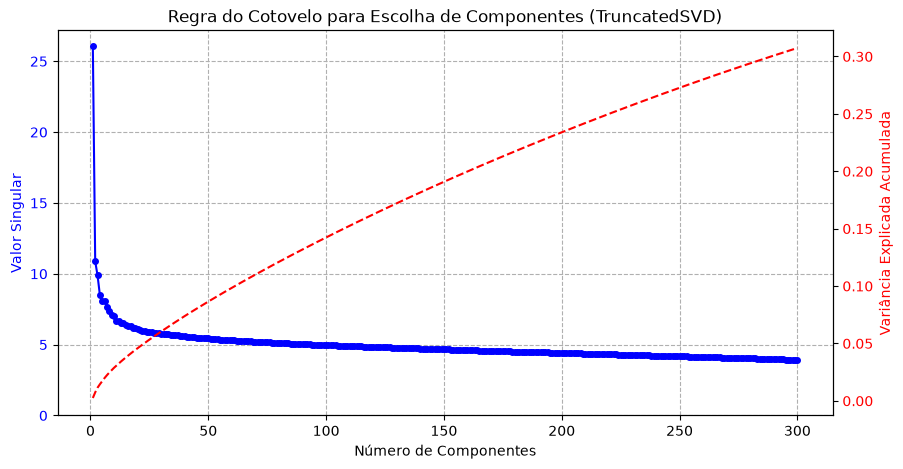

In [45]:

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(range(1, MAX_COMPONENTS + 1), singular_values, 'bo-', label="Valores Singulares", markersize=4)
ax1.set_xlabel('Número de Componentes')
ax1.set_ylabel('Valor Singular', color='b')
ax1.set_ylim(bottom=0)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True, linestyle='--')

ax2 = ax1.twinx()
ax2.plot(range(1, MAX_COMPONENTS + 1), cumulative_variance, 'r--', label="Variância Acumulada")
ax2.set_ylabel('Variância Explicada Acumulada', color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title('Regra do Cotovelo para Escolha de Componentes (TruncatedSVD)')
plt.show()

In [46]:
N_COMPONENTS = 100
RANDOM_STATE = 42
NORM = 'l2'

lsa = make_pipeline(TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE), Normalizer(norm = NORM, copy=False))
X_lsa = lsa.fit_transform(X)

## Primeiro algoritmo de agrupamento: K-means
Para escolher um k para o K-means, plotamos silhueta e inércia para uma faixa de diferentes valores de k. Percebemos que, quando k = 24, a silhueta dá um grande salto e fica numa espécie de platô até o final. Portanto, escolhemos k = 24 para o K-means e o aplicamos.

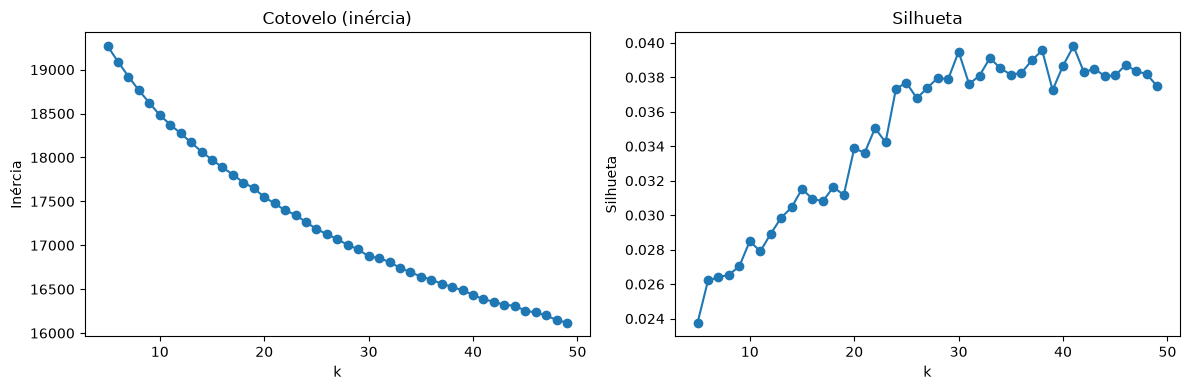

In [47]:
ks = range(5, 50)
inercias, silhuetas = [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_lsa)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_lsa, km.labels_, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercias, marker="o")
ax[0].set(title="Cotovelo (inércia)", xlabel="k", ylabel="Inércia")
ax[1].plot(ks, silhuetas, marker="o")
ax[1].set(title="Silhueta", xlabel="k", ylabel="Silhueta")
plt.tight_layout()
plt.show()

In [48]:
k = 24
km = KMeans(n_clusters=k, random_state=42, n_init=10)
predictions = km.fit_predict(X_lsa)
data["cluster_km"] = pd.Series(predictions, index=data.index)
data.head()

,book_id,title,genre,description,description_raw,cluster_km
0,32941127,Black Panther: A Nation Under Our Feet,graphic-novel|fantasy|science-fiction|literary...,new era black panther begin kingdom wakanda en...,A new era for the Black Panther begins as the ...,13
1,22929618,the Beastly Pirates,children,call beastli pirat fearsom ugli bunch scour se...,They're called The Beastly Pirates and this fe...,20
2,13550502,"The Ill-Made Knight (William Gold, #1)",historical-fiction|literary-fiction|fantasy|no...,william gold come world famili slide social la...,William Gold comes into the world as his famil...,7
3,16059950,The Mystic Princesses and the Whirlpool,children|fantasy,meet mystic princess role model solv problem w...,Meet The Mystic Princesses - Role models who s...,14
4,6684834,88 Short Stories,short-stories,content yvett yvett friend english no anglai r...,Contents: 1. Yvette (Yvette) 2. Our Friends th...,13


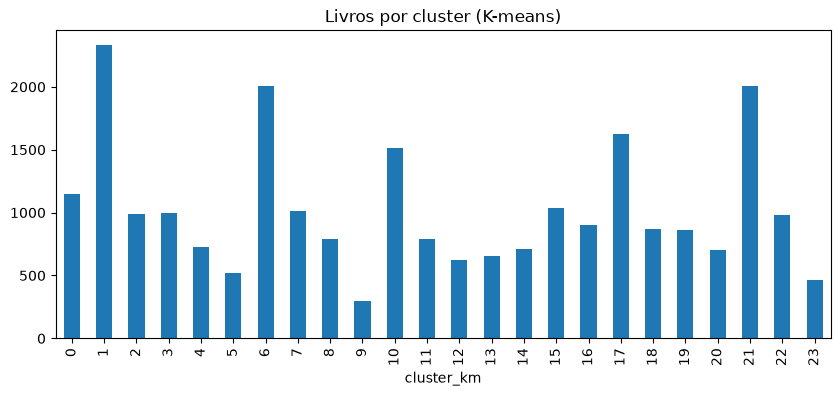

In [49]:
data["cluster_km"].value_counts().sort_index().plot(kind="bar", figsize=(10, 4), title="Livros por cluster (K-means)")
plt.show()

## Validando o K-Means
Ao verificar os termos mais presentes em cada cluster, percebemos uma boa quantidade de sinal e significado nos dados da maioria dos clusters. Alguns exemplos de bons agrupamentos incluem:
- Cluster 2 (_practice, guide, inform, offer_): Aparentam ser textos de cunho prático-informativo, não-ficção
- Cluster 3 (_planet, alien, galaxy, space, ship_): Aparentam ser textos de ficção científica
- Cluster 10 (_murder, case, invest, crime, suspect, victim_): Aparentam ser textos de mistério/investigação criminal




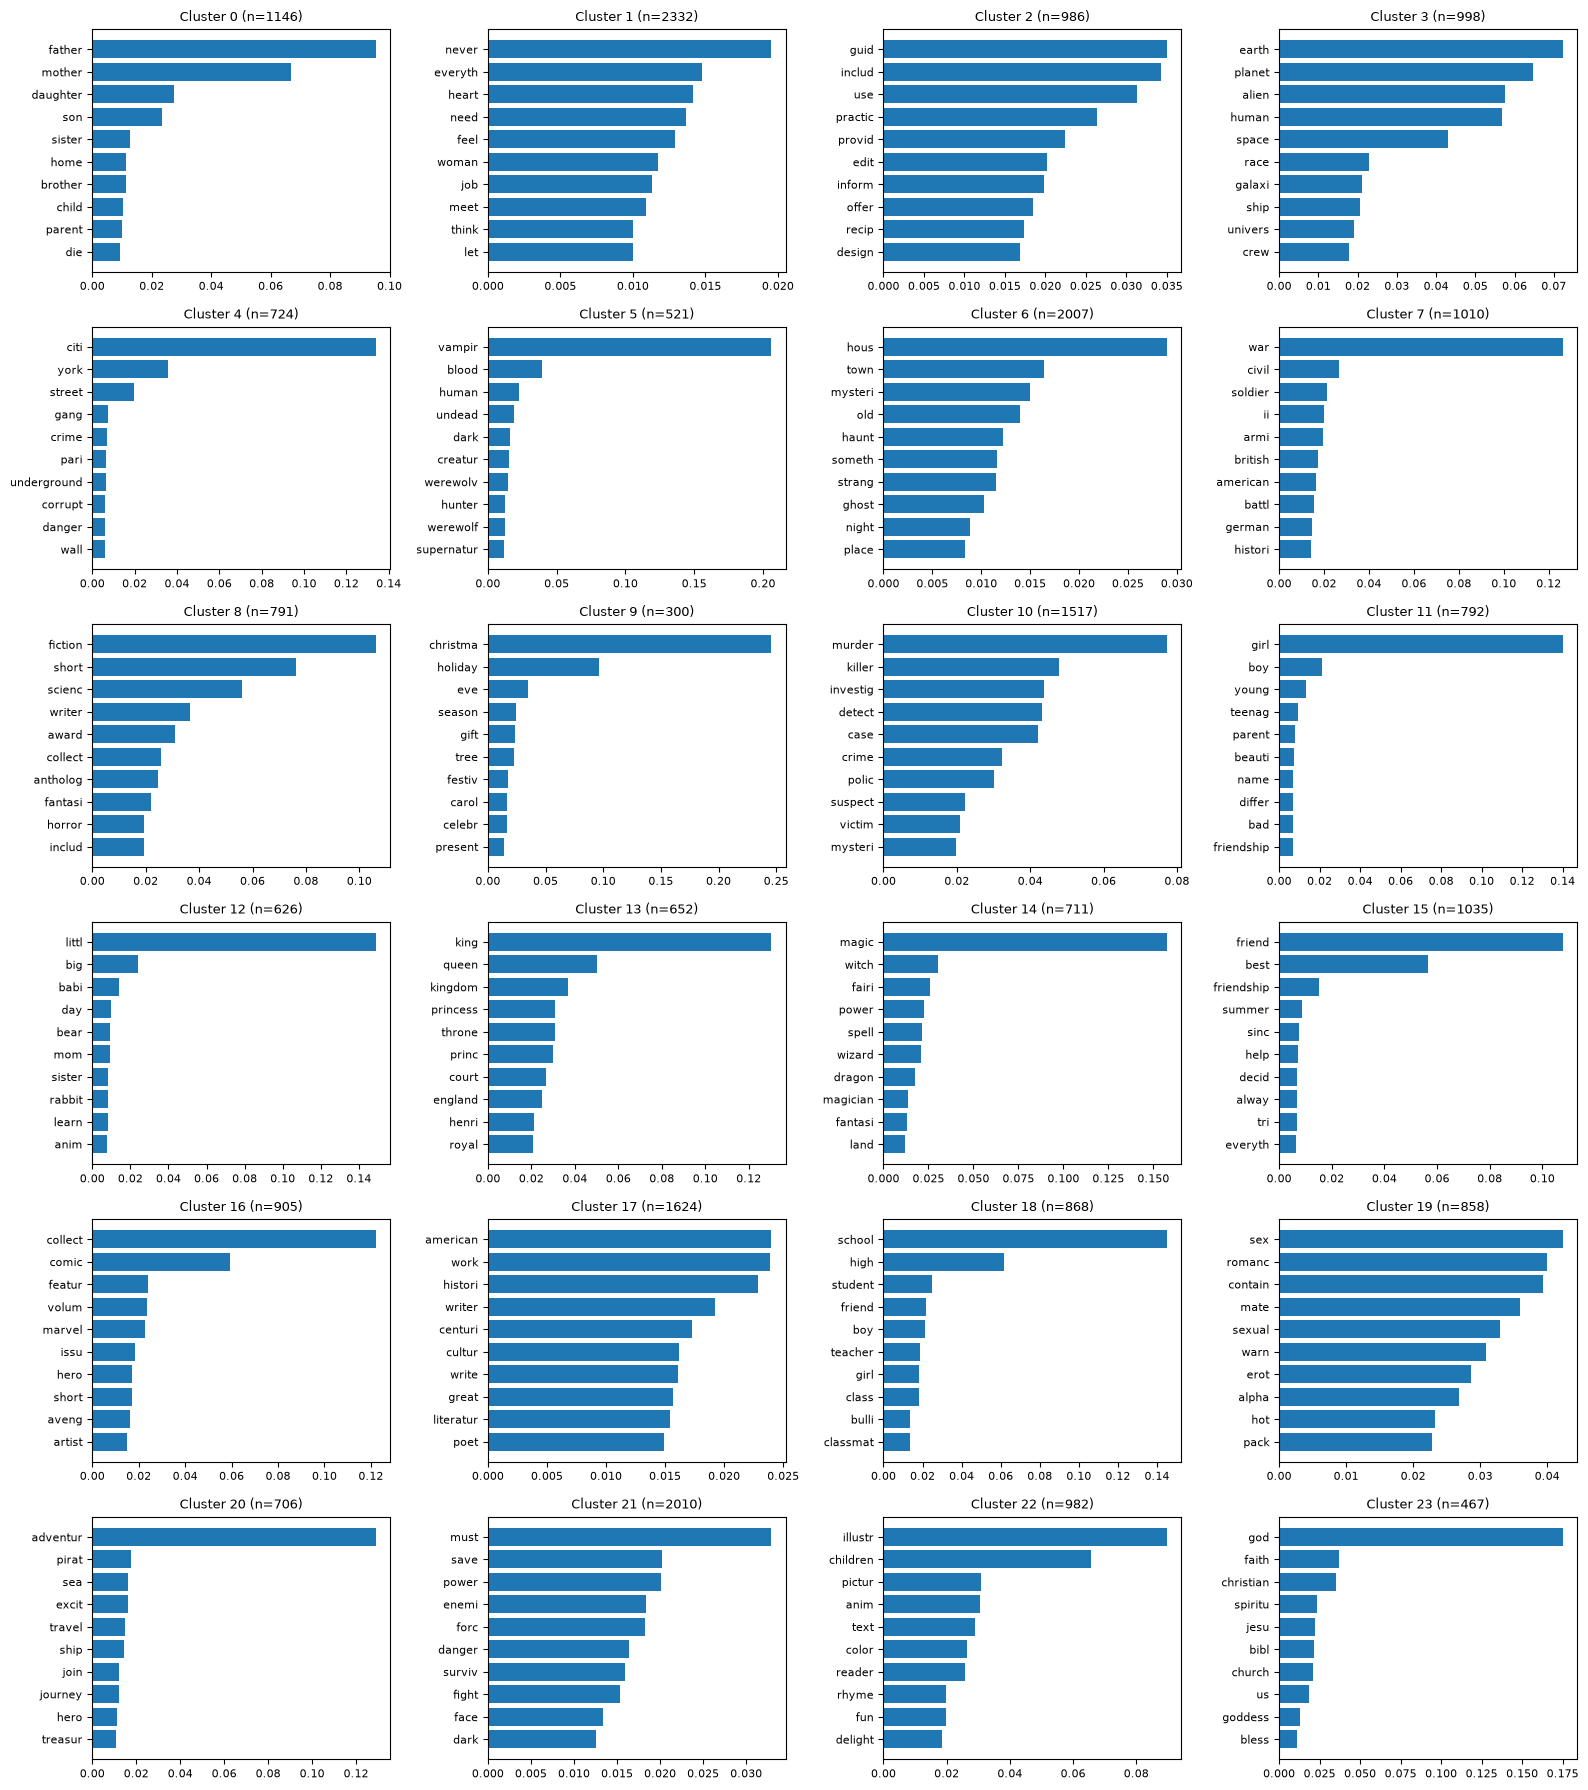

In [50]:
N_TOP = 10
terms = vectorizer.get_feature_names_out()
k = data["cluster_km"].nunique()
mean_all = np.asarray(X.mean(axis=0)).ravel()

ncols = 4
nrows = int(np.ceil(k / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows
))

for c, ax in zip(range(k), axes.flat):
    mask = (data["cluster_km"] == c).to_numpy()
    mean = np.asarray(X[mask].mean(axis=0)).ravel()
    dif = mean - mean_all
    top = dif.argsort()[::-1][:N_TOP]

    ax.barh(terms[top][::-1], dif[top][::-1])
    ax.set_title(f"Cluster {c} (n={mask.sum()})", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[k:]:
    ax.axis("off")

plt.tight_layout()

Além dessa análise visual pelos termos, também analisamos a porcentagem de livros pertencentes a cada gênero por cluster, separando os três predominantes de cada agrupamento. Perceba que, para os clusters do exemplo de análise pelos termos, esses gêneros perceptíveis tiveram porcentagens bem altas.

Uma forma de tentar medir a coesão dos clusters também poderia ser, considerando um critério de porcentagem (50%, 60%, 70%), quantos clusters possuem pelo menos essa porcentagem de livros pertencendo a um mesmo gênero.

In [51]:
genres = data["genre"].str.get_dummies(sep="|")
temp = pd.concat([data, genres], axis=1).drop_duplicates()
temp = temp.groupby("cluster_km")[genres.columns].mean().sort_index()
temp = temp.loc[:, ~temp.columns.duplicated()]
temp

,children,fantasy,graphic-novel,historical-fiction,horror,literary-fiction,mystery,nonfiction,romance,science-fiction,short-stories,young-adult
cluster_km,,,,,,,,,,,,
0,0.157068,0.155323,0.034904,0.303665,0.083770,0.703316,0.229494,0.159686,0.379581,0.080279,0.075044,0.262653
1,0.066895,0.154803,0.045455,0.122642,0.129074,0.453259,0.162093,0.066038,0.637221,0.089623,0.151372,0.165094
2,0.085193,0.058824,0.021298,0.039554,0.045639,0.134888,0.021298,0.870183,0.024341,0.040568,0.034483,0.030426
3,0.059118,0.458918,0.118236,0.027054,0.135271,0.630261,0.112224,0.237475,0.119238,0.840681,0.076152,0.138277
4,0.080110,0.350829,0.136740,0.211326,0.161602,0.690608,0.327348,0.186464,0.180939,0.265193,0.095304,0.193370
5,0.011516,0.777351,0.076775,0.086372,0.798464,0.510557,0.170825,0.028791,0.573896,0.128599,0.115163,0.205374
6,0.141505,0.317389,0.061286,0.218734,0.309417,0.691081,0.360737,0.118087,0.232187,0.151968,0.161933,0.197808
7,0.066337,0.200000,0.077228,0.518812,0.053465,0.640594,0.158416,0.466337,0.176238,0.210891,0.047525,0.104950
8,0.036662,0.351454,0.021492,0.078382,0.225032,0.699115,0.146650,0.187105,0.072061,0.441214,0.662453,0.059418


[Critério 50.0%]: 22/24 (91.66666666666667%)
[Critério 60.0%]: 18/24 (75.0%)
[Critério 70.0%]: 8/24 (33.333333333333336%)


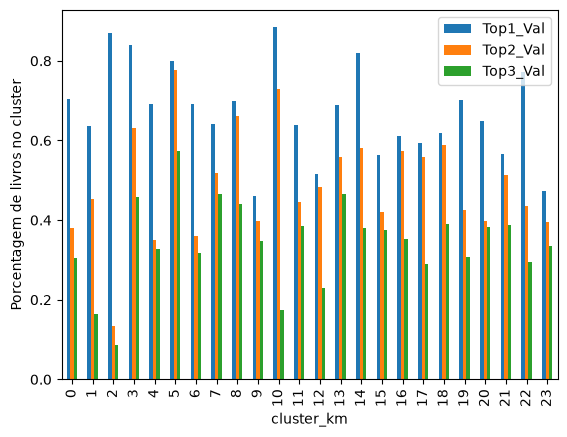

In [52]:
top_genres = temp.apply(lambda row: row.nlargest(3).index, axis=1, result_type='expand')
top_genres.columns = ['Top1', 'Top2', 'Top3']

top_values = temp.apply(lambda row: row.nlargest(3).values, axis=1, result_type='expand')
top_values.columns = ['Top1_Val', 'Top2_Val', 'Top3_Val']

result_km = pd.concat([top_genres, top_values], axis=1)

nClusters = result_km.shape[0]
for criteria in [0.5, 0.6, 0.7]:
    nClustersCrit = result_km[result_km["Top1_Val"] > criteria].shape[0]
    print(f"[Critério {criteria*100}%]: {nClustersCrit}/{nClusters} ({100*nClustersCrit/nClusters}%)")

result_km.plot(y=['Top1_Val', 'Top2_Val', 'Top3_Val'], kind='bar')
plt.ylabel("Porcentagem de livros no cluster"); 
plt.show()

In [53]:
print(result_km.Top1_Val.mean())

0.6719247071401034


In [54]:
result_km

,Top1,Top2,Top3,Top1_Val,Top2_Val,Top3_Val
cluster_km,,,,,,
0,literary-fiction,romance,historical-fiction,0.703316,0.379581,0.303665
1,romance,literary-fiction,young-adult,0.637221,0.453259,0.165094
2,nonfiction,literary-fiction,children,0.870183,0.134888,0.085193
3,science-fiction,literary-fiction,fantasy,0.840681,0.630261,0.458918
4,literary-fiction,fantasy,mystery,0.690608,0.350829,0.327348
5,horror,fantasy,romance,0.798464,0.777351,0.573896
6,literary-fiction,mystery,fantasy,0.691081,0.360737,0.317389
7,literary-fiction,historical-fiction,nonfiction,0.640594,0.518812,0.466337
8,literary-fiction,short-stories,science-fiction,0.699115,0.662453,0.441214


## Segundo algoritmo de agrupamento: Hierárquico/Aglomerativo
Primeiramente, fizemos o dendrograma para analisar a hierarquia de grupos dos documentos no método de linkagem _ward_, que é o que usa um critério semelhante o _K-means_ para agrupar (tenta reduzir a variância interna do cluster a cada link)

A estrutura encnotrada no dendrograma é um pouco difícil de separar em grupos, mas encontramos alguns graus de separação interessantes, como 6, 8 e 16.

{'icoord': [[5.0, 5.0, 15.0, 15.0],
  [25.0, 25.0, 35.0, 35.0],
  [10.0, 10.0, 30.0, 30.0],
  [55.0, 55.0, 65.0, 65.0],
  [45.0, 45.0, 60.0, 60.0],
  [75.0, 75.0, 85.0, 85.0],
  [95.0, 95.0, 105.0, 105.0],
  [115.0, 115.0, 125.0, 125.0],
  [100.0, 100.0, 120.0, 120.0],
  [80.0, 80.0, 110.0, 110.0],
  [52.5, 52.5, 95.0, 95.0],
  [20.0, 20.0, 73.75, 73.75],
  [135.0, 135.0, 145.0, 145.0],
  [175.0, 175.0, 185.0, 185.0],
  [165.0, 165.0, 180.0, 180.0],
  [155.0, 155.0, 172.5, 172.5],
  [140.0, 140.0, 163.75, 163.75],
  [215.0, 215.0, 225.0, 225.0],
  [205.0, 205.0, 220.0, 220.0],
  [195.0, 195.0, 212.5, 212.5],
  [235.0, 235.0, 245.0, 245.0],
  [255.0, 255.0, 265.0, 265.0],
  [275.0, 275.0, 285.0, 285.0],
  [260.0, 260.0, 280.0, 280.0],
  [240.0, 240.0, 270.0, 270.0],
  [203.75, 203.75, 255.0, 255.0],
  [151.875, 151.875, 229.375, 229.375],
  [46.875, 46.875, 190.625, 190.625],
  [295.0, 295.0, 305.0, 305.0],
  [315.0, 315.0, 325.0, 325.0],
  [300.0, 300.0, 320.0, 320.0],
  [335.0, 335.0,

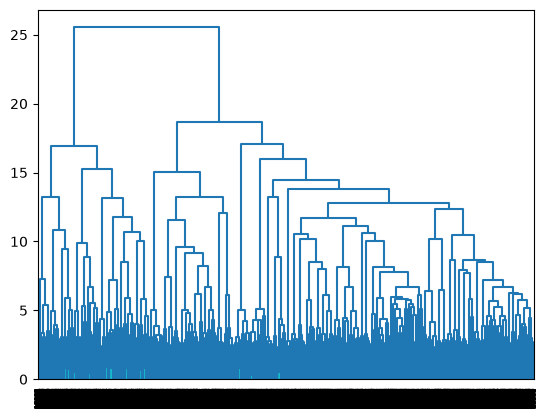

In [ ]:
METHOD = "ward"

Z = hierarchy.linkage(X_lsa, method=METHOD,random_state=42)
hierarchy.dendrogram(Z, color_threshold=1)

In [56]:
m = AgglomerativeClustering(16, linkage = 'ward')
predictions = m.fit_predict(X_lsa)
data["cluster_ac"] = pd.Series(predictions, index=data.index)
data.head()

,book_id,title,genre,description,description_raw,cluster_km,cluster_ac
0,32941127,Black Panther: A Nation Under Our Feet,graphic-novel|fantasy|science-fiction|literary...,new era black panther begin kingdom wakanda en...,A new era for the Black Panther begins as the ...,13,4
1,22929618,the Beastly Pirates,children,call beastli pirat fearsom ugli bunch scour se...,They're called The Beastly Pirates and this fe...,20,4
2,13550502,"The Ill-Made Knight (William Gold, #1)",historical-fiction|literary-fiction|fantasy|no...,william gold come world famili slide social la...,William Gold comes into the world as his famil...,7,2
3,16059950,The Mystic Princesses and the Whirlpool,children|fantasy,meet mystic princess role model solv problem w...,Meet The Mystic Princesses - Role models who s...,14,6
4,6684834,88 Short Stories,short-stories,content yvett yvett friend english no anglai r...,Contents: 1. Yvette (Yvette) 2. Our Friends th...,13,0


## Validando o agrupamento Hierárquico
Seguimos os mesmos processos que usamos para avaliar o K-means.
- Verificação da distribuição dos gêneros em cada cluster
- Verigicação dos top 3 gêneros por cluster
- Critérios de 50%, 60% e 70% de livros num cluster pertencendo a um mesmo gênero

Além disso, fizemos também a análise pelos termos frequentes nos clusters, a qual trouxe resultados bem coesos, semelhantes ao K-means.

In [57]:
genres = data["genre"].str.get_dummies(sep="|")
temp = pd.concat([data, genres], axis=1).drop_duplicates()
temp = temp.groupby("cluster_ac")[genres.columns].mean().sort_index()
temp = temp.loc[:, ~temp.columns.duplicated()]
temp

,children,fantasy,graphic-novel,historical-fiction,horror,literary-fiction,mystery,nonfiction,romance,science-fiction,short-stories,young-adult
cluster_ac,,,,,,,,,,,,
0,0.231504,0.656325,0.094272,0.317422,0.107399,0.646778,0.125298,0.193317,0.303103,0.115752,0.112172,0.312649
1,0.083295,0.107358,0.031004,0.175845,0.062008,0.391485,0.057844,0.644146,0.090699,0.068950,0.132346,0.055067
2,0.113688,0.264154,0.072028,0.218221,0.161148,0.618343,0.295132,0.163589,0.319701,0.168015,0.121471,0.171830
3,0.179084,0.239704,0.070569,0.115919,0.170523,0.529385,0.191347,0.100879,0.410921,0.134891,0.144146,0.273716
4,0.067675,0.517958,0.094518,0.132703,0.259735,0.615501,0.228355,0.153875,0.253686,0.403403,0.061248,0.217013
5,0.073702,0.350084,0.795645,0.035176,0.127303,0.577889,0.134003,0.108878,0.050251,0.345059,0.150754,0.125628
6,0.602696,0.178430,0.101507,0.103093,0.042030,0.443299,0.062649,0.291832,0.066614,0.064235,0.083267,0.103886
7,0.179464,0.197321,0.061607,0.263393,0.114286,0.667857,0.241964,0.135714,0.366071,0.105357,0.071429,0.273214
8,0.013871,0.134931,0.031526,0.128625,0.150063,0.726356,0.904161,0.092055,0.180328,0.078184,0.044136,0.044136


[Critério 50.0%]: 14/16 (87.5%)
[Critério 60.0%]: 12/16 (75.0%)
[Critério 70.0%]: 4/16 (25.0%)


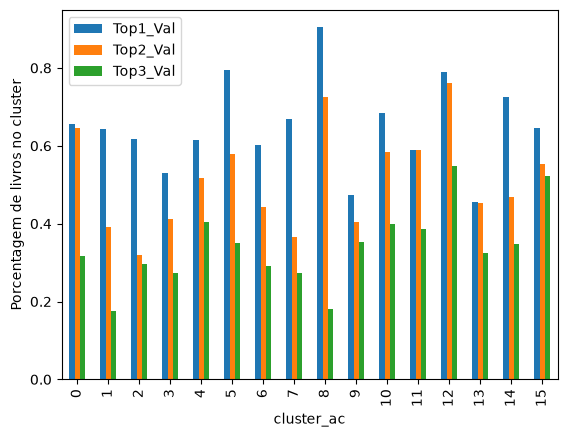

In [58]:
top_genres = temp.apply(lambda row: row.nlargest(3).index, axis=1, result_type='expand')
top_genres.columns = ['Top1', 'Top2', 'Top3']

top_values = temp.apply(lambda row: row.nlargest(3).values, axis=1, result_type='expand')
top_values.columns = ['Top1_Val', 'Top2_Val', 'Top3_Val']

result_ac = pd.concat([top_genres, top_values], axis=1)

nClusters = result_ac.shape[0]
for criteria in [0.5, 0.6, 0.7]:
    nClustersCrit = result_ac[result_ac["Top1_Val"] > criteria].shape[0]
    print(f"[Critério {criteria*100}%]: {nClustersCrit}/{nClusters} ({100*nClustersCrit/nClusters}%)")
    
result_ac.plot(y=['Top1_Val', 'Top2_Val', 'Top3_Val'], kind='bar')
plt.ylabel("Porcentagem de livros no cluster"); 
plt.show()

In [59]:
print(result_ac.Top1_Val.mean())

0.6497787338465586


In [60]:
result_ac

,Top1,Top2,Top3,Top1_Val,Top2_Val,Top3_Val
cluster_ac,,,,,,
0,fantasy,literary-fiction,historical-fiction,0.656325,0.646778,0.317422
1,nonfiction,literary-fiction,historical-fiction,0.644146,0.391485,0.175845
2,literary-fiction,romance,mystery,0.618343,0.319701,0.295132
3,literary-fiction,romance,young-adult,0.529385,0.410921,0.273716
4,literary-fiction,fantasy,science-fiction,0.615501,0.517958,0.403403
5,graphic-novel,literary-fiction,fantasy,0.795645,0.577889,0.350084
6,children,literary-fiction,nonfiction,0.602696,0.443299,0.291832
7,literary-fiction,romance,young-adult,0.667857,0.366071,0.273214
8,mystery,literary-fiction,romance,0.904161,0.726356,0.180328


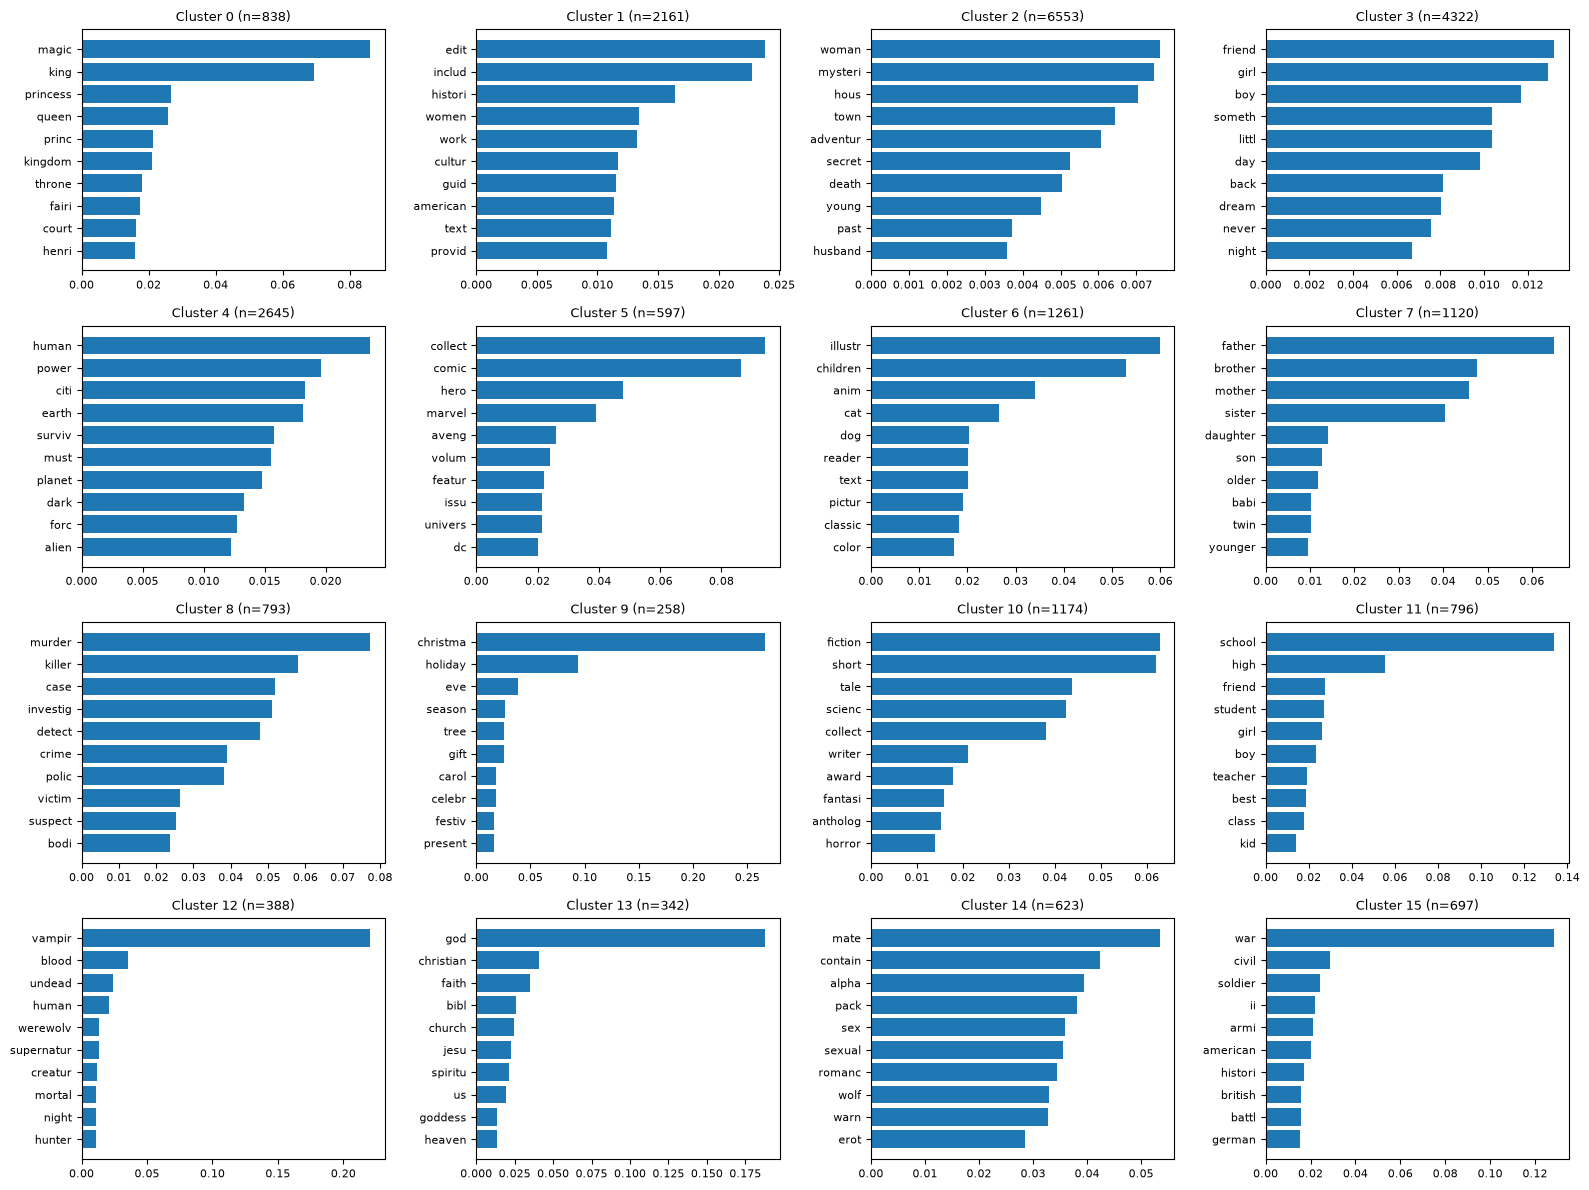

In [61]:
N_TOP = 10
terms = vectorizer.get_feature_names_out()
k = data["cluster_ac"].nunique()
mean_all = np.asarray(X.mean(axis=0)).ravel()

ncols = 4
nrows = int(np.ceil(k / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows
))

for c, ax in zip(range(k), axes.flat):
    mask = (data["cluster_ac"] == c).to_numpy()
    mean = np.asarray(X[mask].mean(axis=0)).ravel()
    dif = mean - mean_all
    top = dif.argsort()[::-1][:N_TOP]

    ax.barh(terms[top][::-1], dif[top][::-1])
    ax.set_title(f"Cluster {c} (n={mask.sum()})", fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[k:]:
    ax.axis("off")

plt.tight_layout()

## Abordagem com LLM

Para resolver o problema utilizando LLMs e embeddings, optamos por utilizar o modelo 'all-MiniLM-L6-v2'. Além disso, diferente do TF-IDF, estamos utilizando as descrições cruas de textos em inglês, ou seja, não foi utilizado nenhum pré processamento.

In [ ]:
model = SentenceTransformer("all-MiniLM-L6-v2")

documents = data.description_raw.tolist()

genres_list = ['literary-fiction','fantasy','romance','mystery','nonfiction',
               'science-fiction','historical-fiction','children','short-stories','horror','young-adult','graphic-novel']

document_embeddings = model.encode_document(documents,show_progress_bar=True,normalize_embeddings=True)
genres_embeddings = model.encode_document(genres_list,show_progress_bar=True,normalize_embeddings=True)   

print(document_embeddings.shape)  
print(genres_embeddings.shape)  


Batches:  62%|██████▏   | 477/768 [04:32<02:10,  2.23it/s]

Uma diferença que vemos do TF-IDF é que ele cria matrizes esparsas em que a informação relevante esta dividida por todo o espaço. Dessa forma, pares de livros que compartilham termos raros são faceis de serem reconhecidos e agrupados. Entretanto, embeddings são vetores densos em que a informação está concentrada em um espaço bem menor. Logo, é necessário utilizar alguma forma de redução de dimensonaliadde no TF-IDF para conseguir reduzir o ruído da esparsidade (TruncatedSVD) e no embedding não é necessário.

Outra diferença é que por se basear em contagens de palavras, o TF-IDF depende de um pré processamento de qualidade para apresentar melhores resultados, vistos que normalizar palavras, retirar stop word, fazer stemming pode ajudar a reduzir o ruído e o vocabulário. Por outro lado, o modelo que cria o embedding é treinado com linguagem natural, logo ele é capaz de ler a frase toda e identificar o contexto do que está sendo dito. Assim, palavras como 'não', 'sem' e 'depois de' mudam o sentido, e cortá-las deixa o texto num formato diferente do que o modelo viu no treino.

## Agrupando pro K means

Como podemos ver pelos grafícos abaixo, a inércia e silhueta mostram que não existe uma divisão de grupos bem definidas nos embeddings. No dataset, livros podem ter diversos gêneros e quando o modelo calcula o embedding pelas descrições, ele esta mapeando os textos em um novo espaço que representa esses embeddings, por exemplo um livro de fantasia e romance fica, no espaço dos embeddings, entre a região de fantasia e a de romance. Assim, o KMeans é obrigado a colocá-lo num único cluster mesmo que um livro devesse ocupar mais de uma região e isso faz com que a silhueta caia.

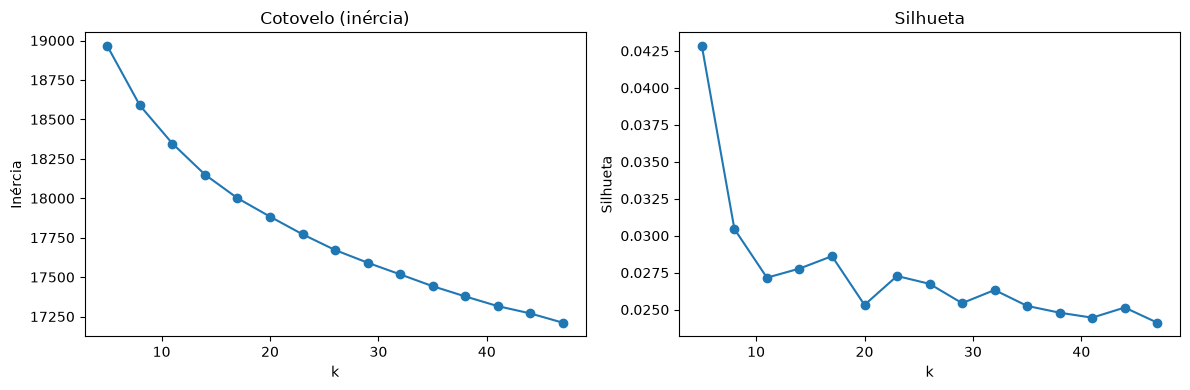

In [ ]:
ks = range(5, 50, 3)
inercias, silhuetas = [], []

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(document_embeddings)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(document_embeddings, km.labels_, random_state=42, metric='cosine'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercias, marker="o")
ax[0].set(title="Cotovelo (inércia)", xlabel="k", ylabel="Inércia")
ax[1].plot(ks, silhuetas, marker="o")
ax[1].set(title="Silhueta", xlabel="k", ylabel="Silhueta")
plt.tight_layout()
plt.show()

Como tivemos dificuldade para definir um k usando métricas internas, iremos utilizar, por efeito de comparação, o mesmo k utilizado no agrupamento do TF-IDF. Dessa forma, podemos comparar diretamente com o mesmo numero de grupos.

In [ ]:
k = 24
km = KMeans(n_clusters=k, random_state=42, n_init=10)
predictions = km.fit_predict(document_embeddings)
data["cluster_embedding"] = pd.Series(predictions, index=data.index)
data.head()

,book_id,title,genre,description,description_raw,cluster_km,cluster_ac,cluster_embedding
0,32941127,Black Panther: A Nation Under Our Feet,graphic-novel|fantasy|science-fiction|literary...,new era black panther begin kingdom wakanda en...,A new era for the Black Panther begins as the ...,13,4,22
1,22929618,the Beastly Pirates,children,call beastli pirat fearsom ugli bunch scour se...,They're called The Beastly Pirates and this fe...,20,4,7
2,13550502,"The Ill-Made Knight (William Gold, #1)",historical-fiction|literary-fiction|fantasy|no...,william gold come world famili slide social la...,William Gold comes into the world as his famil...,7,2,6
3,16059950,The Mystic Princesses and the Whirlpool,children|fantasy,meet mystic princess role model solv problem w...,Meet The Mystic Princesses - Role models who s...,14,6,13
4,6684834,88 Short Stories,short-stories,content yvett yvett friend english no anglai r...,Contents: 1. Yvette (Yvette) 2. Our Friends th...,13,0,5


## Avaliação do agrupamento com embeddings

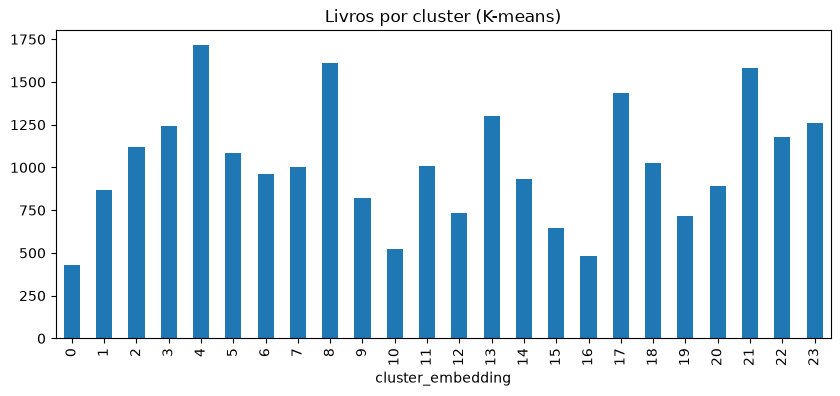

In [ ]:
data["cluster_embedding"].value_counts().sort_index().plot(kind="bar", figsize=(10, 4), title="Livros por cluster (K-means)")
plt.show()

In [ ]:
genres = data["genre"].str.get_dummies(sep="|")
temp = pd.concat([data, genres], axis=1).drop_duplicates()
temp = temp.groupby("cluster_embedding")[genres.columns].mean().sort_index()
temp = temp.loc[:, ~temp.columns.duplicated()]
temp

,children,fantasy,graphic-novel,historical-fiction,horror,literary-fiction,mystery,nonfiction,romance,science-fiction,short-stories,young-adult
cluster_embedding,,,,,,,,,,,,
0,0.459397,0.269142,0.037123,0.090487,0.095128,0.484919,0.097448,0.085847,0.257541,0.030162,0.271462,0.139211
1,0.047235,0.243088,0.103687,0.178571,0.100230,0.629032,0.373272,0.232719,0.124424,0.480415,0.046083,0.112903
2,0.096515,0.472744,0.082216,0.090259,0.668454,0.605898,0.391421,0.089366,0.113494,0.218945,0.250223,0.176944
3,0.091787,0.190821,0.078100,0.133655,0.148148,0.573269,0.358293,0.148148,0.223833,0.137681,0.154589,0.142512
4,0.182401,0.222611,0.042541,0.122960,0.124709,0.649767,0.315851,0.074009,0.448135,0.141026,0.051282,0.446387
5,0.067343,0.142989,0.052583,0.273063,0.080258,0.668819,0.075646,0.477860,0.086716,0.052583,0.250923,0.058118
6,0.061331,0.193347,0.010395,0.709979,0.100832,0.704782,0.220374,0.204782,0.584200,0.061331,0.061331,0.116424
7,0.715285,0.263736,0.095904,0.061938,0.062937,0.507493,0.094905,0.164835,0.055944,0.056943,0.093906,0.136863
8,0.102978,0.162531,0.019851,0.370968,0.098015,0.752481,0.197270,0.228288,0.374069,0.089950,0.153846,0.217122


[Critério 50.0%]: 23/24 (95.83333333333333%)
[Critério 60.0%]: 21/24 (87.5%)
[Critério 70.0%]: 12/24 (50.0%)


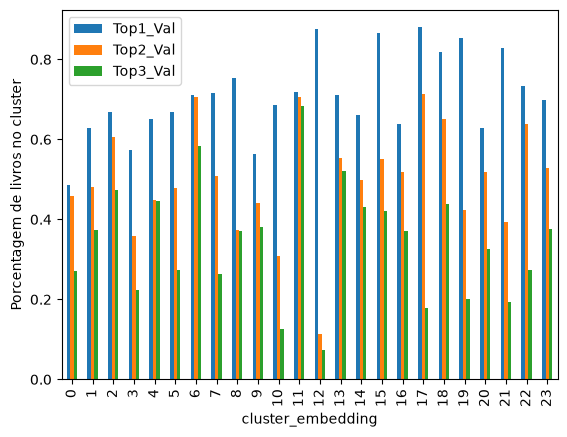

In [ ]:
top_genres = temp.apply(lambda row: row.nlargest(3).index, axis=1, result_type='expand')
top_genres.columns = ['Top1', 'Top2', 'Top3']

top_values = temp.apply(lambda row: row.nlargest(3).values, axis=1, result_type='expand')
top_values.columns = ['Top1_Val', 'Top2_Val', 'Top3_Val']

result_emb = pd.concat([top_genres, top_values], axis=1)

nClusters = result_emb.shape[0]
for criteria in [0.5, 0.6, 0.7]:
    nClustersCrit = result_emb[result_emb["Top1_Val"] > criteria].shape[0]
    print(f"[Critério {criteria*100}%]: {nClustersCrit}/{nClusters} ({100*nClustersCrit/nClusters}%)")
    
result_emb.plot(y=['Top1_Val', 'Top2_Val', 'Top3_Val'], kind='bar')
plt.ylabel("Porcentagem de livros no cluster"); 
plt.show()

In [ ]:
print(result_emb.Top1_Val.mean())

0.7086149952375616


In [ ]:
result_emb

,Top1,Top2,Top3,Top1_Val,Top2_Val,Top3_Val
cluster_embedding,,,,,,
0,literary-fiction,children,short-stories,0.484919,0.459397,0.271462
1,literary-fiction,science-fiction,mystery,0.629032,0.480415,0.373272
2,horror,literary-fiction,fantasy,0.668454,0.605898,0.472744
3,literary-fiction,mystery,romance,0.573269,0.358293,0.223833
4,literary-fiction,romance,young-adult,0.649767,0.448135,0.446387
5,literary-fiction,nonfiction,historical-fiction,0.668819,0.477860,0.273063
6,historical-fiction,literary-fiction,romance,0.709979,0.704782,0.584200
7,children,literary-fiction,fantasy,0.715285,0.507493,0.263736
8,literary-fiction,romance,historical-fiction,0.752481,0.374069,0.370968


Comparando com os valores obtidos no agrupamento utilizando TF-IDF, vemos que o uso de embeddings leva uma certa vantagem principalmente nos critérios de 60% e 70%, tendo um aumento de 12,5 e 16,67 pontos, respectivamente.

## Classificação por similaridade

Para classificar os livros, iremos calcular a similaridade de cosseno entre os embeddings das descrições com os embeddings dos gêneros

In [ ]:
similarities = model.similarity(genres_embeddings, document_embeddings)

tensor([[ 0.0488,  0.2042,  0.2104,  ...,  0.1344,  0.3583,  0.3162],
        [ 0.0603,  0.1444,  0.1205,  ...,  0.0661,  0.1675,  0.2094],
        [-0.0188,  0.1217,  0.1062,  ...,  0.0485,  0.2092,  0.2121],
        ...,
        [ 0.0699,  0.1798,  0.0491,  ...,  0.0375,  0.2343,  0.0954],
        [ 0.0385,  0.1076,  0.0865,  ...,  0.0513,  0.0848,  0.1810],
        [ 0.1777,  0.1761,  0.1334,  ...,  0.0543,  0.2798,  0.2823]])

Pelo report abaixo, vemos que literary fiction foi o gênero que apresentou melhores resultados, visto que este gênero está presente em mais da metade dos livros, logo o resultado é favorecido pela alta frequência. Romance é o segundo lugar em precisão apesar de possuir um recall baixo, ou seja, livros que eram para ser romance mas não foram identificados. Alguns gêneros como graphic-novel e historical-fiction possuem o resultado contrário uma precisão baixa mas com o recall alto, ou seja, o modelo não deixa passar boa parte desses livros mas classifica outros com o gênero errado o que reduz a precisão.

In [ ]:
sim = similarities.T.numpy()
Y_true = data.genre.str.get_dummies(sep="|")[genres_list].to_numpy()
n_true = Y_true.sum(axis=1)
order = np.argsort(-sim, axis=1)

Y_pred = np.zeros_like(Y_true)
for i, row in enumerate(order):
    Y_pred[i, row[:n_true[i]]] = 1
print(classification_report(Y_true, Y_pred, target_names=genres_list, zero_division=0))

                    precision    recall  f1-score   support

  literary-fiction       0.74      0.70      0.72     13904
           fantasy       0.64      0.34      0.44      7085
           romance       0.69      0.52      0.59      7028
           mystery       0.43      0.41      0.42      5345
        nonfiction       0.32      0.30      0.31      4984
   science-fiction       0.56      0.45      0.50      4251
historical-fiction       0.33      0.75      0.46      4175
          children       0.49      0.29      0.37      3544
     short-stories       0.29      0.49      0.36      3374
            horror       0.51      0.36      0.42      4123
       young-adult       0.56      0.10      0.16      4674
     graphic-novel       0.17      0.64      0.27      2137

         micro avg       0.47      0.47      0.47     64624
         macro avg       0.48      0.45      0.42     64624
      weighted avg       0.54      0.47      0.48     64624
       samples avg       0.42      0.4

Podemos fazer a mesma analíse mas agora atribuindo apenas um gênero para cada livro, ou seja, tomando apenas o gênero com mais similariade.

In [ ]:
top1 = sim.argmax(axis=1)

Y_pred_top1 = np.zeros_like(Y_true)
Y_pred_top1[np.arange(len(Y_true)), top1] = 1

print("Top-1:", (Y_true[np.arange(len(Y_true)), top1] == 1).mean())
print(classification_report(Y_true, Y_pred_top1, target_names=genres_list, zero_division=0))

Top-1: 0.5031748616085966
                    precision    recall  f1-score   support

  literary-fiction       0.66      0.24      0.35     13904
           fantasy       0.57      0.09      0.15      7085
           romance       0.71      0.30      0.42      7028
           mystery       0.47      0.18      0.26      5345
        nonfiction       0.41      0.10      0.17      4984
   science-fiction       0.60      0.12      0.20      4251
historical-fiction       0.38      0.38      0.38      4175
          children       0.57      0.16      0.25      3544
     short-stories       0.38      0.24      0.30      3374
            horror       0.54      0.12      0.19      4123
       young-adult       0.39      0.02      0.04      4674
     graphic-novel       0.28      0.37      0.32      2137

         micro avg       0.50      0.19      0.28     64624
         macro avg       0.50      0.19      0.25     64624
      weighted avg       0.54      0.19      0.26     64624
       sampl

Algo a se destacar é ver que o recall cai bastante (0,47 - 0,19) visto que cada livro recebe uma única previsão, mas a maioria tem mais de um gênero. Os outros gêneros do livro nunca são previstos e contam como falsos negativos reduzindo o recall. Além disso, nesse método a precisão média sobe um pouco comparado ao anterior (0,47 - 0,50). Na maioria dos gêneros a precisão sobe alguns pontos como children e nonfiction, entretanto literary-fiction, fantasy e young adult tiverem queda de precisão, uma justificativa para isso pode ser que frequentemente em livros com multiplos gêneros eles aparecem como gêneros secundários o que eleva sua precisão no método anterior.

Além disso, outro ponto interessante é que historical-fiction e graphic-novel fogem a regra e apresentam recall igual ou maiores que o precision em ambos os métodos. Uma interpretação para isso é que no espaço dos embeddings, esses gêneros ficam próximos de muitas descrições, causando esse resultado.


## Conclusão

Em primeiro lugar, ficou evidente que, sem métodos de redução de dimensionalidade (como o ajuste do min_df e das componentes do svd), seria inviável computar os algoritmos de agrupamento. Notamos que, sem min_df, o TF-IDF gerava mais de 110 mil features, o que era impraticável. Por isso, usando da regra do cotovelo tanto para o min_df como para o TruncatedSVD, foi possível reduzir a dimensionalidade dos dados de forma coerente, sem perder muita informação, mas ao mesmo tempo mantendo o problema computacionalmente viável.

Ao final dos agrupamentos, conseguimos observar que os grupos feitos a partir das descrições faziam sentido, na maior parte dos casos, em relação ao seu gênero. Além disso, vimos que diferentes grupos gerados em cada método de agrupamento possuíam distribuições de gêneros significativamente diferentes entre si ao analisar os três maiores de gêneros de cada grupo. 

A qualidade do agrupamento do k-means foi um pouco superior ao hierárquico mas nada comparado a diferença ao utilizar o k-means com embeddings feitos por LLMs, nas quais fizeram grupos bem concetrados, como foi visto nos critérios de 50 a 70%.